# Conversational Search Retrieval Augmented Generation

In this notebook you will implement the following steps:

- **Answer selection + evaluation**: Implement a *search-based* conversation framework evaluation framework to evaluate conversation topics made up of conversation turns.
- **Answer ranking**: Implement a *re-ranking method* to sort the initial search results. Evaluate the re-ranked results.
- **Conversation memory**: Implement a conversational context modeling method to keep track of the conversation state. 

Submission dates:
- **20 October**: first stage retrieval + conversation memory + evaluation
- **15 November**: re-ranking with LLM + evaluation
- **15 December**: answer generation + evaluation

## Test bed and conversation topics
The TREC CAST corpus (http://www.treccast.ai/) for Conversational Search is indexed in this cluster and available to be searched behind an OpenSearch API.

The queries and the relevance judgments are available through class `ConvSearchEvaluation`:

In [1]:
from importlib import reload
import TRECCASTeval as trec
import numpy as np
import pprint

import numpy as np

pp = pprint.PrettyPrinter(indent=4)

test_bed = trec.ConvSearchEvaluation()

print()
print("========================================== Training conversations =====")
topics = {}
for topic in test_bed.train_topics:
    conv_id = topic['number']

    if conv_id not in (1, 2, 4, 7, 15, 17,18,22,23,24,25,27,30):
        continue

    print()
    print(conv_id, "  ", topic['title'])

    for turn in topic['turn']:
        turn_id = turn['number']
        utterance = turn['raw_utterance']
        topic_turn_id = '%d_%d'% (conv_id, turn_id)
        
        print(topic_turn_id, utterance)
        topics[topic_turn_id] = utterance

print()
print("========================================== Test conversations =====")
for topic in test_bed.test_topics:
    conv_id = topic['number']

    if conv_id not in (31, 32, 33, 34, 37, 40, 49, 50, 54, 56, 58, 59, 61, 67, 68, 69, 75, 77, 78, 79):
        continue

    print()
    print(conv_id, "  ", topic['title'])

    for turn in topic['turn']:
        turn_id = turn['number']
        utterance = turn['raw_utterance']
        topic_turn_id = '%d_%d'% (conv_id, turn_id)
        
        print(topic_turn_id, utterance)
        topics[topic_turn_id] = utterance



========================================== Training conversations =====

1    Career choice for Nursing and Physician's Assistant
1_1 What is a physician's assistant?
1_2 What are the educational requirements required to become one?
1_3 What does it cost?
1_4 What's the average starting salary in the UK?
1_5 What about in the US?
1_6 What school subjects are needed to become a registered nurse?
1_7 What is the PA average salary vs an RN?
1_8 What the difference between a PA and a nurse practitioner?
1_9 Do NPs or PAs make more?
1_10 Is a PA above a NP?
1_11 What is the fastest way to become a NP?
1_12 How much longer does it take to become a doctor after being an NP?

2    Goat breeds
2_1 What are the main breeds of goat?
2_2 Tell me about boer goats.
2_3 What breed is good for meat?
2_4 Are angora goats good for it?
2_5 What about boer goats?
2_6 What are pygmies used for?
2_7 What is the best for fiber production?
2_8 How long do Angora goats live?
2_9 Can you milk them?
2_10 How ma

## OpenSearch

In [2]:
import OpenSearchSimpleAPI as osearch
import pprint as pp
opensearch = osearch.OSsimpleAPI()

Search example:

In [4]:
results = opensearch.search_body(topics['33_1'], numDocs = 10)
print(results)

  _index _type                                           _id     _score  \
0   kwiz  _doc                                   MARCO_34196  21.662935   
1   kwiz  _doc  CAR_c370ef5df77de117ff7d02c4b64b52f5bae9abc9  21.348211   
2   kwiz  _doc                                 MARCO_6213095  19.961092   
3   kwiz  _doc  CAR_77e4e91100d10a01d66980d12c1911b2480188f2  19.919603   
4   kwiz  _doc  CAR_bc696d8a1aa65b9ad1457552248018e22bda9a46  18.935474   
5   kwiz  _doc  CAR_8e3edf1d911122ff30fe58b9105bd77b7a897779  18.773558   
6   kwiz  _doc                                 MARCO_3498132  18.748793   
7   kwiz  _doc  CAR_68b5fe44a03559eaddb929ff8a3d934f1c566ab9  18.744522   
8   kwiz  _doc  CAR_d8b9c8cd14e85fb25782d482c49fc76b7da590ed  18.562819   
9   kwiz  _doc  CAR_161e2edabf7e5d5394c93756067f1a38a6ce29c3  18.320707   

                                    _source.contents  \
0  The holidays are prime time for family storyte...   
1  The NeverEnding Story III: Escape from Fantasi...   
2  The

In [4]:
opensearch.doc_term_vectors('MARCO_34196')

(23596,
 1405893,
 2299289,
 {'a': [4, 17146, 48957],
  'about': [2, 2688, 3958],
  'alex': [1, 36, 79],
  'and': [2, 19644, 68602],
  'are': [1, 8821, 17501],
  'at': [1, 4726, 7343],
  'been': [1, 2550, 3343],
  'best': [1, 990, 1687],
  'bits': [2, 26, 30],
  'bitsâ': [1, 1, 1],
  'can': [1, 4720, 7495],
  'catches': [1, 12, 16],
  'children': [1, 362, 559],
  'chris': [1, 63, 77],
  'dadâ': [1, 1, 1],
  'dark': [1, 333, 454],
  'else': [1, 104, 114],
  'everyone': [1, 106, 130],
  'family': [1, 555, 775],
  'for': [2, 9865, 18393],
  'friend': [1, 130, 156],
  'from': [1, 7167, 11274],
  'funny': [1, 26, 28],
  'gory': [1, 2, 2],
  'hand': [1, 311, 415],
  'has': [2, 3998, 5765],
  'having': [1, 503, 579],
  'himself': [1, 246, 289],
  'his': [2, 2353, 5180],
  'holiday': [1, 46, 60],
  'holidays': [2, 19, 21],
  'in': [2, 17309, 52844],
  'into': [1, 2473, 3267],
  'invite': [1, 5, 5],
  'just': [1, 909, 1128],
  'kids': [1, 88, 135],
  'leave': [1, 131, 153],
  'little': [1, 436,

In [5]:
# sum_doc_freq: 
# doc_count: 
# sum_ttf: 
# doc_freq: 
# ttf: 
# term_freq: 
opensearch.termvectors_JSON(doc_id='MARCO_34196')

{'_index': 'kwiz',
 '_type': '_doc',
 '_id': 'MARCO_34196',
 '_version': 1,
 'found': True,
 'took': 0,
 'term_vectors': {'contents': {'field_statistics': {'sum_doc_freq': 1405893,
    'doc_count': 23596,
    'sum_ttf': 2299289},
   'terms': {'a': {'doc_freq': 17146, 'ttf': 48957, 'term_freq': 4},
    'about': {'doc_freq': 2688, 'ttf': 3958, 'term_freq': 2},
    'alex': {'doc_freq': 36, 'ttf': 79, 'term_freq': 1},
    'and': {'doc_freq': 19644, 'ttf': 68602, 'term_freq': 2},
    'are': {'doc_freq': 8821, 'ttf': 17501, 'term_freq': 1},
    'at': {'doc_freq': 4726, 'ttf': 7343, 'term_freq': 1},
    'been': {'doc_freq': 2550, 'ttf': 3343, 'term_freq': 1},
    'best': {'doc_freq': 990, 'ttf': 1687, 'term_freq': 1},
    'bits': {'doc_freq': 26, 'ttf': 30, 'term_freq': 2},
    'bitsâ': {'doc_freq': 1, 'ttf': 1, 'term_freq': 1},
    'can': {'doc_freq': 4720, 'ttf': 7495, 'term_freq': 1},
    'catches': {'doc_freq': 12, 'ttf': 16, 'term_freq': 1},
    'children': {'doc_freq': 362, 'ttf': 559, 

In [6]:
opensearch.get_doc_body('MARCO_34196')

'The holidays are prime time for family storytelling. When youâ\x80\x99re putting up the tree or having your holiday meal, share a story with your children about past holidays. Leave in the funny bits, the sad bits, the gory and smelly bitsâ\x80\x93kids can tell when a story has been sanitized for their protection.Then invite everyone else to tell a story too.Dad, tell me a story from when you were little. Tell me the story about the time you met your best friend Chris at school.â\x80\x9d Six-year-old Alex, who has just started school himself, snuggles into his pillow and catches his dadâ\x80\x99s hand in the dark.'

In [7]:
example_doc = 'The film only adapts the first half of the book, and consequently does not convey the message of the title as it was portrayed in the novel. The second half of the book would subsequently be used as the rough basis for the second film, The NeverEnding Story II: The Next Chapter.The third film, The NeverEnding Story III: Escape From Fantasia, features a completely original plot.he second half of the book would subsequently be used as the rough basis for the second film, The NeverEnding Story II: The Next Chapter.'
opensearch.query_terms(example_doc,'standard')

' the film only adapts the first half of the book and consequently does not convey the message of the title as it was portrayed in the novel the second half of the book would subsequently be used as the rough basis for the second film the neverending story ii the next chapter.the third film the neverending story iii escape from fantasia features a completely original plot.he second half of the book would subsequently be used as the rough basis for the second film the neverending story ii the next chapter'

In [8]:
opensearch.analyzer(analyzer="standard", query=example_doc)

{'tokens': [{'token': 'the',
   'start_offset': 0,
   'end_offset': 3,
   'type': '<ALPHANUM>',
   'position': 0},
  {'token': 'film',
   'start_offset': 4,
   'end_offset': 8,
   'type': '<ALPHANUM>',
   'position': 1},
  {'token': 'only',
   'start_offset': 9,
   'end_offset': 13,
   'type': '<ALPHANUM>',
   'position': 2},
  {'token': 'adapts',
   'start_offset': 14,
   'end_offset': 20,
   'type': '<ALPHANUM>',
   'position': 3},
  {'token': 'the',
   'start_offset': 21,
   'end_offset': 24,
   'type': '<ALPHANUM>',
   'position': 4},
  {'token': 'first',
   'start_offset': 25,
   'end_offset': 30,
   'type': '<ALPHANUM>',
   'position': 5},
  {'token': 'half',
   'start_offset': 31,
   'end_offset': 35,
   'type': '<ALPHANUM>',
   'position': 6},
  {'token': 'of',
   'start_offset': 36,
   'end_offset': 38,
   'type': '<ALPHANUM>',
   'position': 7},
  {'token': 'the',
   'start_offset': 39,
   'end_offset': 42,
   'type': '<ALPHANUM>',
   'position': 8},
  {'token': 'book',
   's

## Retrieval with training conversations
The OpenSearchSimpleAPI notebook illustrates how to use OpenSearch. Use this API to retrieve the top 100 ranked passages for each conversation turn. 

To evaluate the results you should use the provided `ConvSearchEvaluation` class. Examine and discuss the recall metric results. In terms of metrics, discuss what should be your goals for each step of the project.

C:\Users\rmcg0\AppData\Local\Temp\ipykernel_8896\2360143857.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()



P10= 0.15728155339805822   Recall= 0.6699724628122686   NDCG@5= 0.2088312547271504   AP= 0.22150690254001845



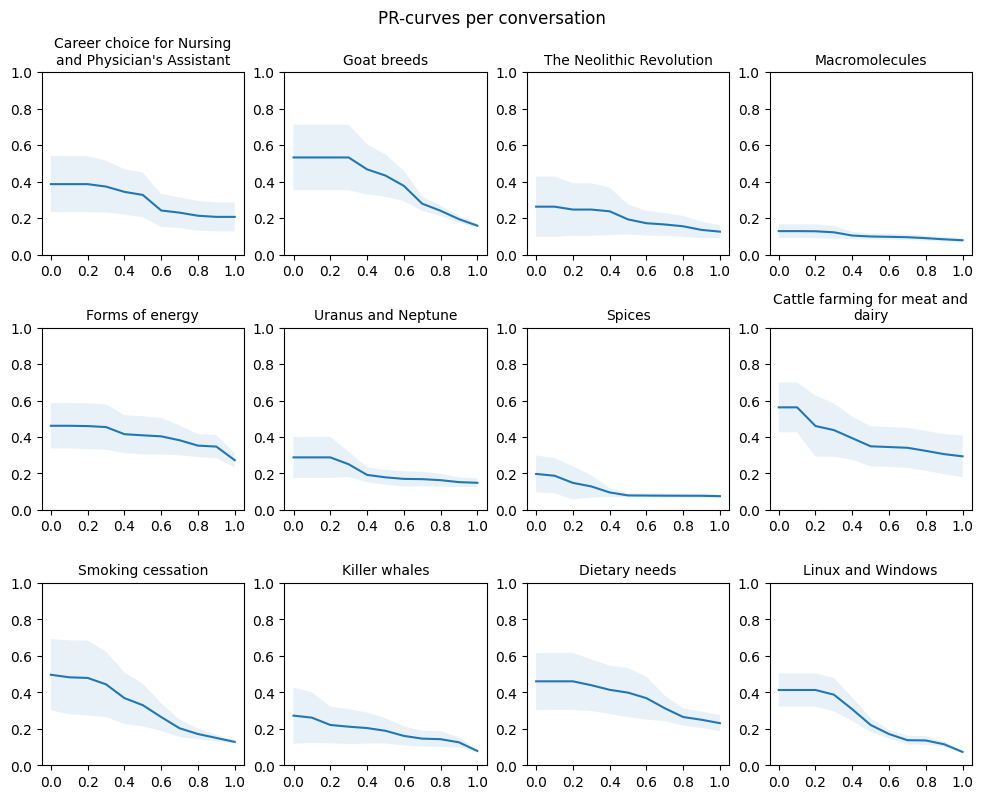

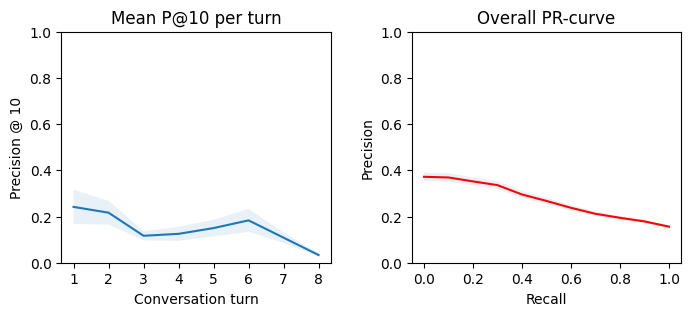

In [3]:
from importlib import reload
import TRECCASTeval as trec
import matplotlib.pyplot as plt
import numpy as np
from textwrap import wrap
import OpenSearchSimpleAPI as osearch
import pprint as pp

osearch = reload(osearch)
trec = reload(trec)

opensearch = osearch.OSsimpleAPI()
test_bed = trec.ConvSearchEvaluation()
conv_topics = test_bed.train_topics
selected_topics = (1, 2, 4, 7, 17,18,22,23,24,25,27,30)

fig = plt.figure(1, figsize= [12,9])
fig.subplots_adjust(hspace = 0.4)
fig.show()
fig.suptitle("PR-curves per conversation", y=0.95)

_ndcg5_acc = np.zeros((len(selected_topics),12))
_p10_acc = np.zeros((len(selected_topics),12))
_recall = 0
_p10 = 0
_ndcg5 = 0
_ap = 0
_full_mean_prec_rec = []

verbose = False
_nturns = 0
_conv_count = 0
for topic in conv_topics:
    
    conv_id = topic['number']
    title = topic['title']

    if conv_id not in selected_topics:
        continue

    if verbose:
        print(title)
    
    _precision_11point = []
    _turn_count = -1
    for turn in topic['turn']:
        _turn_count = _turn_count + 1
        turn_id = turn['number']
        utterance = turn['raw_utterance']
        topic_turn_id = '%d_%d'% (conv_id, turn_id)
        
        result = opensearch.search_body(query=utterance, numDocs = 100)

        num_rel = test_bed.num_rel(topic_turn_id)
        
        if num_rel == 0:
            _p10_acc[_conv_count, _turn_count] = 0
            _ndcg5_acc[_conv_count, _turn_count] = 0
            continue

        if np.size(result) == 0:
            continue

        if verbose:
            print(topic_turn_id, opensearch.query_terms(utterance,'standard'))

        [p10, recall, ap, ndcg5] = test_bed.eval(result[['_id','_score','_source.doc']], topic_turn_id, verbose = False)
        _p10_acc[_conv_count, _turn_count] = p10
        _ndcg5_acc[_conv_count, _turn_count] = ndcg5
        _recall = _recall + recall
        _p10 = _p10 + p10
        _ndcg5 = _ndcg5 + ndcg5
        _ap = _ap + ap
        
        [precision_11point, recall_11point, total_relv_ret] = test_bed.evalPR(result[['_id','_score', '_source.doc']], topic_turn_id)
        _precision_11point.append(precision_11point)

        _nturns = _nturns + 1

    mean_prec_rec = np.asarray(_precision_11point ).mean(axis=0)
    var_prec_rec = np.asarray(_precision_11point ).var(axis=0)
    _full_mean_prec_rec.append(mean_prec_rec)

    recall_11point = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    ax = fig.add_subplot(3,4,_conv_count+1)
    ax.set_ylim([0.0,1.0])
    title = conv_topics[conv_id-1]['title']
    if len(title) > 30:
        ax.set_title("\n".join(wrap(title, 28)), fontsize=10)
    else:
        ax.set_title(title, fontsize=10)
    ax.fill_between(recall_11point, mean_prec_rec - var_prec_rec, mean_prec_rec + var_prec_rec, alpha = 0.1)
    ax.set_xticks(np.arange(0,1.1,0.2))
    ax.plot(recall_11point, mean_prec_rec)
    _conv_count = _conv_count + 1

_p10 = _p10/_nturns
_recall = _recall/_nturns
_ndcg5 = _ndcg5/_nturns
_ap = _ap/_nturns

fig_2 = plt.figure(2, figsize= [8,3])
fig_2.subplots_adjust(wspace = 0.3)

mean_p10_per_turn = np.mean(_p10_acc,axis = 0)
var_p10_per_turn = np.var(_p10_acc,axis = 0)
ax1 = fig_2.add_subplot(1,2,1)
ax1.plot(np.arange(1,9), mean_p10_per_turn[0:8])
ax1.set_xticks(np.arange(1,9))
ax1.fill_between(np.arange(1,9), mean_p10_per_turn[0:8]-var_p10_per_turn[0:8], mean_p10_per_turn[0:8]+var_p10_per_turn[0:8], alpha = 0.1)
ax1.set_ylim([0.0,1.0])
ax1.set_xlabel("Conversation turn")
ax1.set_ylabel("Precision @ 10")
ax1.set_title("Mean P@10 per turn")

ax2 = fig_2.add_subplot(1,2,2)
full_mean_prec_rec = np.asarray(_full_mean_prec_rec ).mean(axis=0)
full_var_prec_rec = np.asarray(_full_mean_prec_rec ).var(axis=0)
ax2.plot(recall_11point, full_mean_prec_rec, color='red')
ax2.fill_between(recall_11point, full_mean_prec_rec - full_var_prec_rec, full_mean_prec_rec + full_var_prec_rec, alpha = 0.1)
ax2.set_ylim([0.0,1.0])
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.set_title("Overall PR-curve")

print()
print('P10=', _p10, '  Recall=', _recall, '  NDCG@5=', _ndcg5, '  AP=', _ap)
print()


## Retrieval with the test conversations

C:\Users\rmcg0\AppData\Local\Temp\ipykernel_8896\3626620027.py:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()



P10= 0.2479768786127168   Recall= 0.36321449772336045   NDCG@5= 0.15978119270171204   AP= 0.1534098010023894



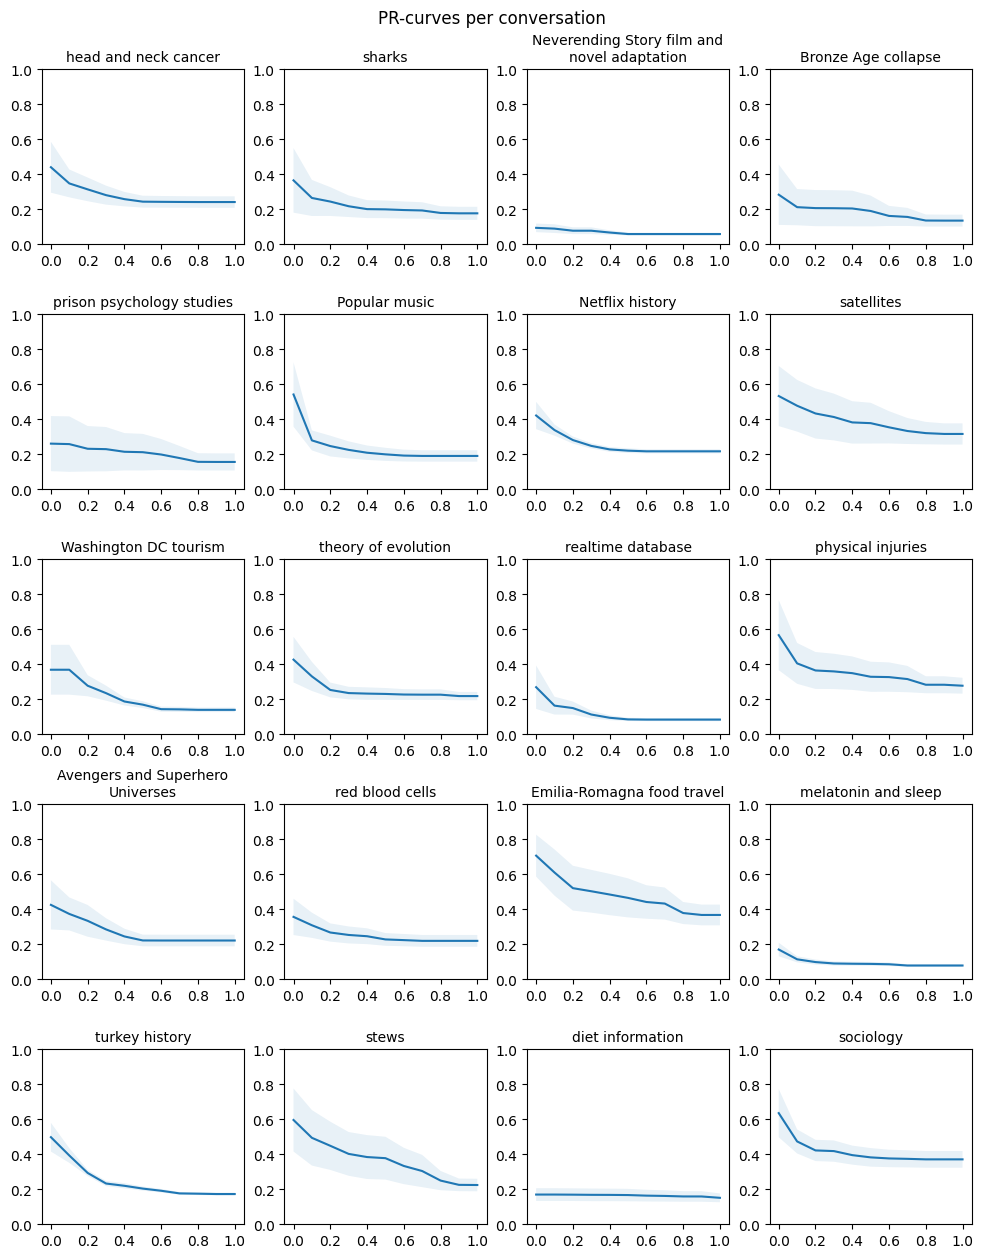

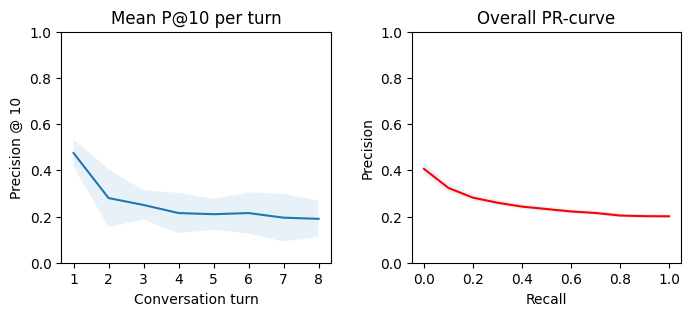

In [4]:
from importlib import reload
import TRECCASTeval as trec
import matplotlib.pyplot as plt
import numpy as np
from textwrap import wrap
import OpenSearchSimpleAPI as osearch
import pprint as pp

osearch = reload(osearch)
trec = reload(trec)

opensearch = osearch.OSsimpleAPI()

test_bed = trec.ConvSearchEvaluation()
conv_topics = test_bed.test_topics
verbose = False
selected_topics = (31, 32, 33, 34, 37, 40, 49, 50, 54, 56, 58, 59, 61, 67, 68, 69, 75, 77, 78, 79)



fig = plt.figure(1, figsize= [12,15])
fig.subplots_adjust(hspace = 0.4)
fig.show()
fig.suptitle("PR-curves per conversation", y=0.92)

_ndcg5_acc = np.zeros((len(selected_topics),12))
_p10_acc = np.zeros((len(selected_topics),12))
_recall = 0
_p10 = 0
_ndcg5 = 0
_ap = 0
_full_mean_prec_rec = []


_nturns = 0
_conv_count = 0
for topic in conv_topics:
    
    conv_id = topic['number']
    title = topic['title']
    
    if conv_id not in selected_topics:
        continue

    if verbose:
        print(title)

    _precision_11point = []
    _turn_count = -1
    for turn in topic['turn']:
        _turn_count = _turn_count + 1
        turn_id = turn['number']
        utterance = turn['raw_utterance']
        topic_turn_id = '%d_%d'% (conv_id, turn_id)
        
        result = opensearch.search_body(query=utterance, numDocs = 100)

        num_rel = test_bed.num_rel(topic_turn_id)
        
        if num_rel == 0:
            _p10_acc[_conv_count, _turn_count] = 0
            _ndcg5_acc[_conv_count, _turn_count] = 0
            continue

        if np.size(result) == 0:
            continue

        if verbose:
            print(topic_turn_id, opensearch.query_terms(utterance,'standard'))

        [p10, recall, ap, ndcg5] = test_bed.eval(result[['_id','_score','_source.doc']], topic_turn_id, verbose = False)
        _p10_acc[_conv_count, _turn_count] = p10
        _ndcg5_acc[_conv_count, _turn_count] = ndcg5
        _recall = _recall + recall
        _p10 = _p10 + p10
        _ndcg5 = _ndcg5 + ndcg5
        _ap = _ap + ap
        
        [precision_11point, recall_11point, total_relv_ret] = test_bed.evalPR(result[['_id','_score', '_source.doc']], topic_turn_id)
        _precision_11point.append(precision_11point)

        _nturns = _nturns + 1

    mean_prec_rec = np.asarray(_precision_11point ).mean(axis=0)
    var_prec_rec = np.asarray(_precision_11point ).var(axis=0)
    _full_mean_prec_rec.append(mean_prec_rec)

    recall_11point = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    ax = fig.add_subplot(5, 4, _conv_count+1)
    ax.set_ylim([0.0,1.0])
    if len(title) > 30:
        ax.set_title("\n".join(wrap(title, 28)), fontsize=10)
    else:
        ax.set_title(title, fontsize=10)
    ax.fill_between(recall_11point, mean_prec_rec - var_prec_rec, mean_prec_rec + var_prec_rec, alpha = 0.1)
    ax.set_xticks(np.arange(0,1.1,0.2))
    ax.plot(recall_11point, mean_prec_rec)
    _conv_count = _conv_count + 1

_p10 = _p10/_nturns
_recall = _recall/_nturns
_ndcg5 = _ndcg5/_nturns
_ap = _ap/_nturns

fig_2 = plt.figure(2, figsize= [8,3])
fig_2.subplots_adjust(wspace = 0.3)

mean_p10_per_turn = np.mean(_p10_acc,axis = 0)
var_p10_per_turn = np.var(_p10_acc,axis = 0)
ax1 = fig_2.add_subplot(1,2,1)
ax1.plot(np.arange(1,9), mean_p10_per_turn[0:8])
ax1.set_xticks(np.arange(1,9))
ax1.fill_between(np.arange(1,9), mean_p10_per_turn[0:8]-var_p10_per_turn[0:8], mean_p10_per_turn[0:8]+var_p10_per_turn[0:8], alpha = 0.1)
ax1.set_ylim([0.0,1.0])
ax1.set_xlabel("Conversation turn")
ax1.set_ylabel("Precision @ 10")
ax1.set_title("Mean P@10 per turn")

ax2 = fig_2.add_subplot(1,2,2)
full_mean_prec_rec = np.asarray(_full_mean_prec_rec ).mean(axis=0)
full_var_prec_rec = np.asarray(_full_mean_prec_rec ).var(axis=0)
ax2.plot(recall_11point, full_mean_prec_rec, color='red')
ax2.fill_between(recall_11point, full_mean_prec_rec - full_var_prec_rec, full_mean_prec_rec + full_var_prec_rec, alpha = 0.1)
ax2.set_ylim([0.0,1.0])
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.set_title("Overall PR-curve")

print()
print('P10=', _p10, '  Recall=', _recall, '  NDCG@5=', _ndcg5, '  AP=', _ap)
print()
